# TCS Stock: Linear Regression — OHLCV vs OHLCV + Indicators
**Target:** Next_Day_Close = Close.shift(-1) | **Split:** 80/20 time-based | **Dataset:** TCS.csv (2005–2026)

**Structure:**
1. Load data → EDA → Visualizations
2. Part A: Linear Regression on OHLCV Only (5 features)
3. Part B: Linear Regression on OHLCV + Indicators (14 features)
4. Part C: Compare A vs B
5. Part D: Overfitting / Underfitting Check

## Step 0: Data Collection — Download TCS Stock Data from Yahoo Finance

**Source:** Yahoo Finance via `yfinance` library
**Stock:** TCS.NS (TCS listed on NSE — National Stock Exchange, India)
**Period:** 2005-01-01 to 2026-09-24
**Saved as:** TCS.csv

This is the raw data collection step. The downloaded CSV contains:
Open, High, Low, Close, Volume — daily historical data adjusted for stock splits and dividends.

In [1]:
pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import yfinance as yf
yf.download('TCS.NS', start='2005-01-01', end='2026-09-24').to_csv('TCS.csv')
print("TCS.csv downloaded and saved successfully!")

[*********************100%***********************]  1 of 1 completed

TCS.csv downloaded and saved successfully!


---
## Step 1: Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

print("Libraries imported successfully!")

Libraries imported successfully!


---
## Step 2: Load Dataset
`TCS.csv` has 2 extra yfinance header rows — skip with `skiprows=[1,2]`. Rename 'Price' → 'Date'.

In [57]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

for col in ['Open','High','Low','Close','Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print("Dataset loaded!")
print(f"Rows: {len(df)}")

Dataset loaded!
Rows: 5363


---
## Step 3: Dataset Overview

In [5]:
print(f"Shape     : {df.shape}")
print(f"Date Range: {df.index[0].date()} to {df.index[-1].date()}")
print(f"Columns   : {list(df.columns)}")

Shape     : (5363, 5)
Date Range: 2005-01-03 to 2026-09-23
Columns   : ['Open', 'High', 'Low', 'Close', 'Volume']


In [6]:
print("Column Names and Data Types:")
print(df.dtypes)

Column Names and Data Types:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [7]:
print("First 5 Rows:")
df.head()

First 5 Rows:


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,106.848537,108.547923,106.848537,108.272697,4734168
2005-01-04,108.011852,108.331887,106.664507,107.312576,4979104
2005-01-05,107.227811,107.227811,102.435290,106.011681,9604320
2005-01-06,105.611583,107.691811,103.411342,105.648384,8006888
2005-01-07,106.411726,107.611858,105.024376,107.208611,7623136


In [8]:
print("Missing Values per Column:")
print(df.isnull().sum())
print(f"Total missing: {df.isnull().sum().sum()}")

Missing Values per Column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Total missing: 0


In [9]:
print(f"Duplicate Rows: {df.duplicated().sum()}")

Duplicate Rows: 0


In [10]:
print("Statistical Summary:")
df[['Open','High','Low','Close','Volume']].describe().round(2)

Statistical Summary:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1344.44,1357.71,1330.29,1343.67,3350520.35
std,1188.95,1199.08,1178.30,1188.29,2819411.07
min,75.80,78.58,69.43,75.49,0.00
25%,274.27,277.70,270.58,274.01,1853218.00
50%,959.55,967.05,951.04,958.63,2650784.00
75%,2383.67,2414.17,2349.66,2376.28,3987019.00
max,4251.38,4266.48,4191.92,4230.71,88067154.00


---
## Step 4: EDA Graphs

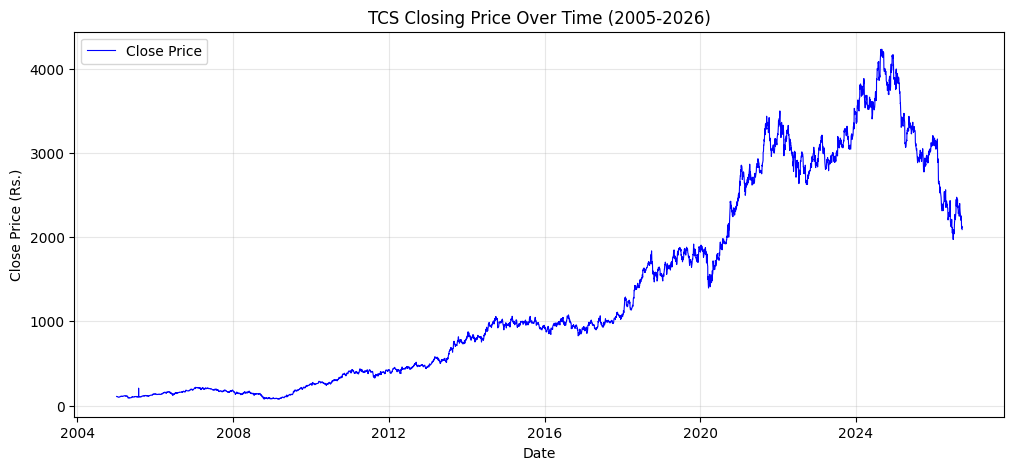

In [11]:
# Graph 1: Close Price over time
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Close'], color='blue', linewidth=0.8, label='Close Price')
plt.xlabel('Date')
plt.ylabel('Close Price (Rs.)')
plt.title('TCS Closing Price Over Time (2005-2026)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

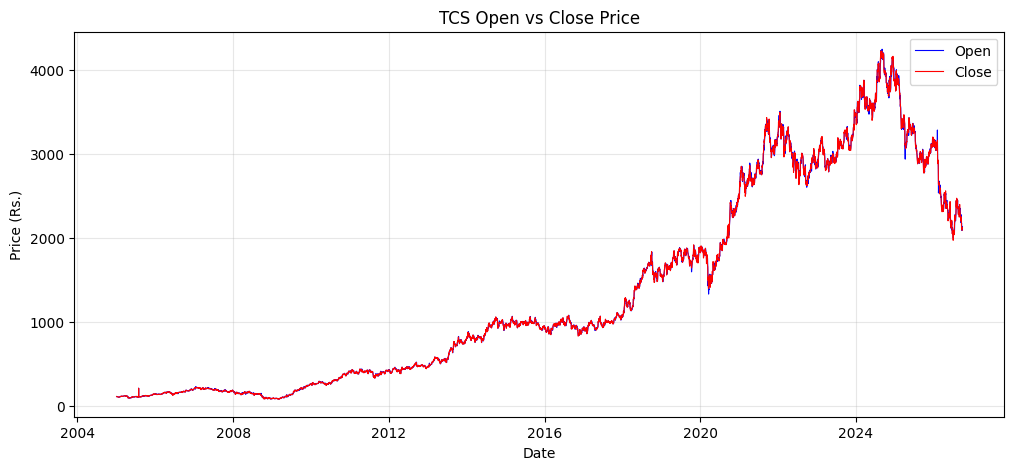

In [12]:
# Graph 2: Open vs Close
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Open'],  color='blue', linewidth=0.8, label='Open')
plt.plot(df.index, df['Close'], color='red',  linewidth=0.8, label='Close')
plt.xlabel('Date')
plt.ylabel('Price (Rs.)')
plt.title('TCS Open vs Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

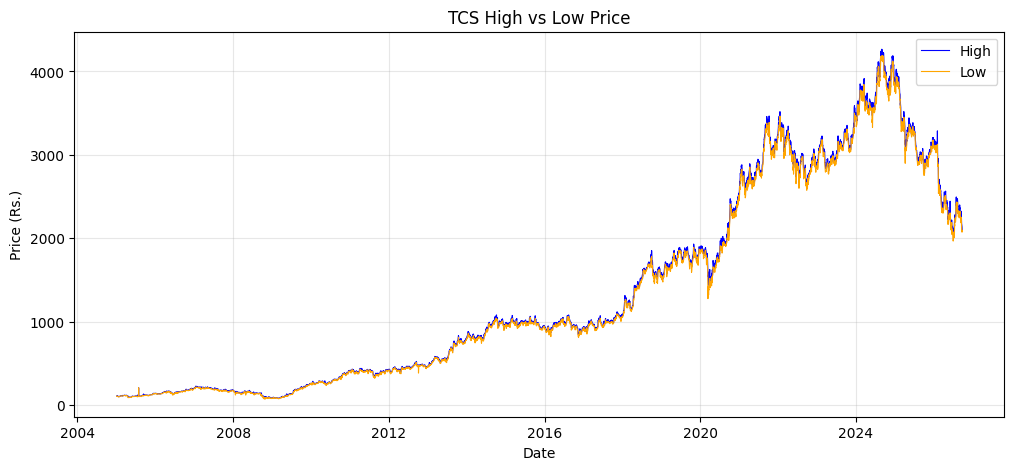

In [13]:
# Graph 3: High vs Low
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['High'], color='blue',   linewidth=0.8, label='High')
plt.plot(df.index, df['Low'],  color='orange', linewidth=0.8, label='Low')
plt.xlabel('Date')
plt.ylabel('Price (Rs.)')
plt.title('TCS High vs Low Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

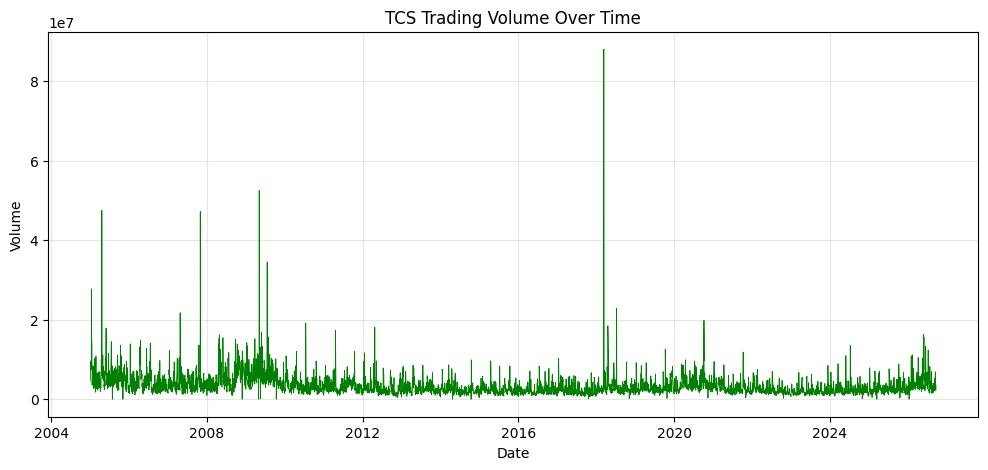

In [14]:
# Graph 4: Volume
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Volume'], color='green', linewidth=0.6)
plt.xlabel('Date')
plt.ylabel('Volume')
plt.title('TCS Trading Volume Over Time')
plt.grid(True, alpha=0.3)
plt.show()

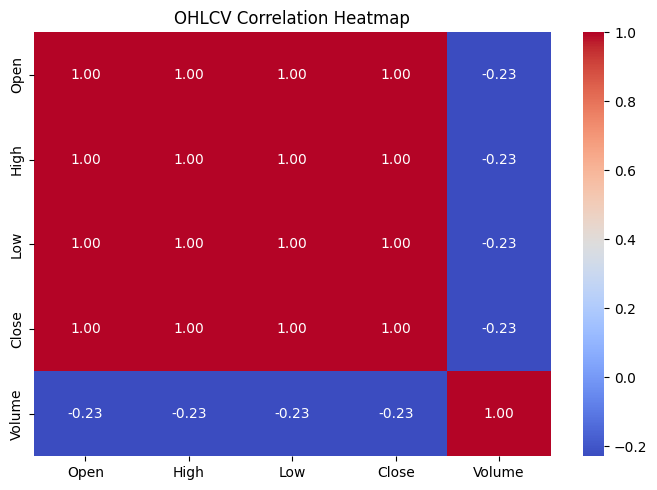

In [15]:
# Graph 5: OHLCV Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[['Open','High','Low','Close','Volume']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm')
plt.title('OHLCV Correlation Heatmap')
plt.tight_layout()
plt.show()

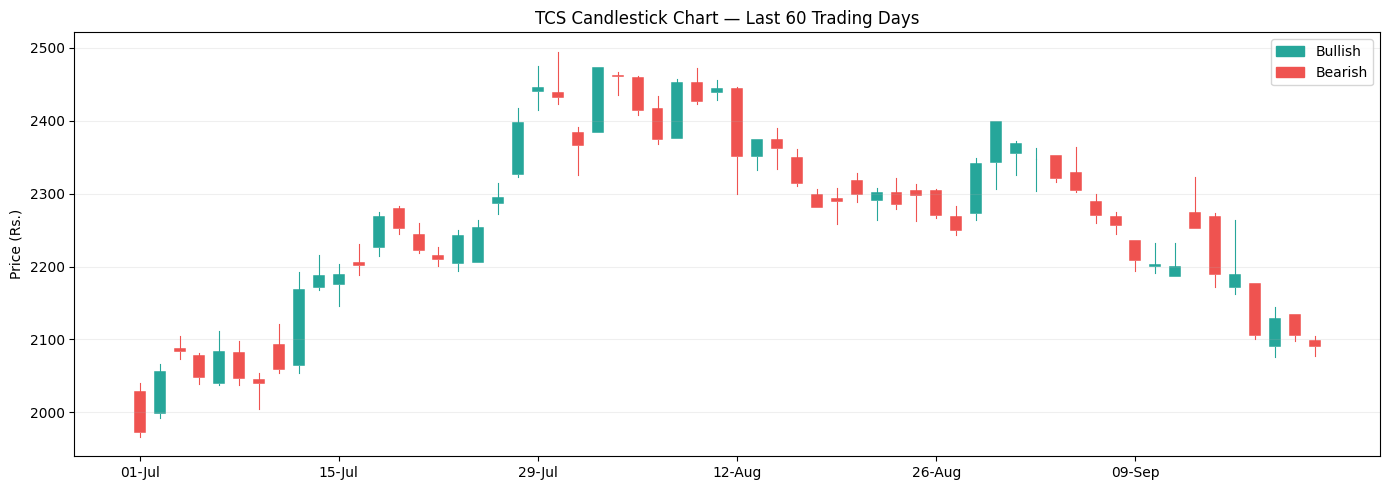

In [16]:
# Graph 6: Candlestick — Last 60 Days
import matplotlib.patches as mpatches
last60 = df.tail(60).copy()
fig, ax = plt.subplots(figsize=(14, 5))
for i, (date, row) in enumerate(last60.iterrows()):
    c = '#26A69A' if row['Close'] >= row['Open'] else '#EF5350'
    ax.bar(i, abs(row['Close']-row['Open']), bottom=min(row['Open'],row['Close']),
           color=c, width=0.6, edgecolor='white', linewidth=0.3)
    ax.plot([i,i],[max(row['Open'],row['Close']), row['High']], color=c, linewidth=0.8)
    ax.plot([i,i],[min(row['Open'],row['Close']), row['Low']],  color=c, linewidth=0.8)
ticks = range(0, 60, 10)
ax.set_xticks(ticks)
ax.set_xticklabels([last60.index[i].strftime('%d-%b') for i in ticks])
ax.set_title('TCS Candlestick Chart — Last 60 Trading Days')
ax.set_ylabel('Price (Rs.)')
ax.legend(handles=[mpatches.Patch(color='#26A69A', label='Bullish'),
                   mpatches.Patch(color='#EF5350', label='Bearish')])
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.show()

---
## Step 5: Create Target Variable
`Next_Day_Close = Close.shift(-1)` — each row now stores tomorrow's closing price.
Last row gets NaN (no tomorrow) — drop it.

In [17]:
df['Next_Day_Close'] = df['Close'].shift(-1)
df.dropna(subset=['Next_Day_Close'], inplace=True)
print(f"Target created. Total rows: {len(df)}")
df[['Close', 'Next_Day_Close']].head(5)

Target created. Total rows: 5362


,Close,Next_Day_Close
Date,,
2005-01-03,108.272697,107.312576
2005-01-04,107.312576,106.011681
2005-01-05,106.011681,105.648384
2005-01-06,105.648384,107.208611
2005-01-07,107.208611,106.208519


### Feature Engineering — Research Paper Basis

The following technical indicators were selected based on their proven effectiveness in stock price prediction literature:

| Indicator | Research Basis | What it captures |
|-----------|---------------|-----------------|
| **MA_7, MA_30** | Brock et al. (1992) | Short/long-term price trends |
| **EMA_12, EMA_26** | Murphy (1999) | Exponentially weighted recent trends |
| **MACD** | Appel (1979) | Price momentum and direction change |
| **RSI_14** | Wilder (1978) | Overbought/oversold market sentiment |
| **Volatility** | Engle (1982) | Risk and price instability measure |
| **Daily_Return** | Fama (1965) | Daily percentage price movement |
| **Lag1_Close** | Box & Jenkins (1970) | Autoregressive: past price predicts future |

> *Key sources:*
> - *Patel et al. (2015). Predicting stock price index movement using ML. Expert Systems with Applications.*
> - *Fischer & Krauss (2018). Deep learning with long short-term memory networks for financial market predictions.*
> - *Brock, Lakonishok & LeBaron (1992). Simple technical trading rules and stochastic properties of stock returns.*

**Why these 9 indicators on top of OHLCV?**
> Raw OHLCV data captures WHAT happened (prices, volume).
> Technical indicators capture WHY it happened (momentum, trend, volatility).
> Combining both gives the model both historical context AND market sentiment.